In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:42521")
client

<Client: 'tcp://127.0.0.1:42521' processes=8 threads=32, memory=503.70 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op

from scipy.interpolate import griddata

import xrft
import gsw

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
la = np.arange(10,60,10)
dlo = 11.5
lo = np.arange(-96.,-15,11.5)

In [5]:
# for pp in range(7,9):
#     if pp == 7:
#         ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
#                             ).chunk({"time":10,"y":400,"x":400})
#     else:
#         tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
#                             ).chunk({"time":10,"y":400,"x":400}
#                                    ).isel(time=slice(1,None))
#         time = tmp.time.data + ds.time[-1].data
#         tmp = tmp.reset_index("time", drop=False)
#         tmp = tmp.reset_coords("time", drop=True)
#         tmp.coords["time"] = ("time", time)
#         ds = xr.concat([ds, tmp], "time")
#         tmp.close()
dsb = xr.open_zarr(op.join(ddir,"SW/mean/UVh.zarr"))
dsp  = xr.open_zarr(op.join(ddir,"SW/TWA/Up.zarr"))
dspp = xr.open_zarr(op.join(ddir,"SW/TWA/Upp.zarr"))
# dpv = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi.zarr"))
dpvb2z = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/b-to-Z.zarr"))
# dpvz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ.zarr"))
dpvz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InZ_grad1st.zarr"))

dsb, dsp, dspp, dpvz

(<xarray.Dataset> Size: 671MB
 Dimensions:  (level: 4, y: 2048, x: 4096)
 Coordinates:
   * level    (level) float32 16B 1.0 2.0 3.0 4.0
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
 Data variables:
     hbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     ubar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     uhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     vbar     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>
     vhat     (level, y, x) float32 134MB dask.array<chunksize=(1, 256, 512), meta=np.ndarray>,
 <xarray.Dataset> Size: 141GB
 Dimensions:  (time: 419, level: 5, y: 2048, x: 4096)
 Coordinates:
   * time     (time) float32 2kB 0.0 2.592e+06 5.184e+06 ... 1.081e+09 1.083e+09
   * level    (level) float32 20B

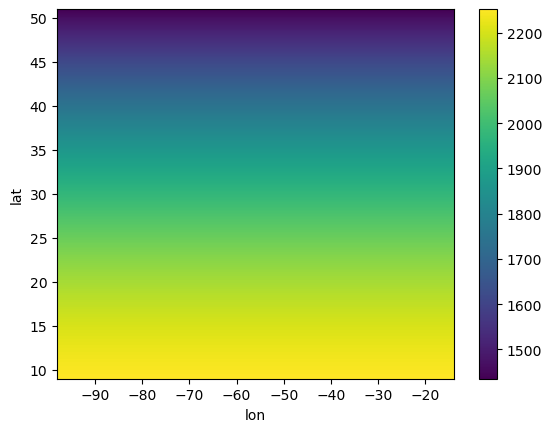

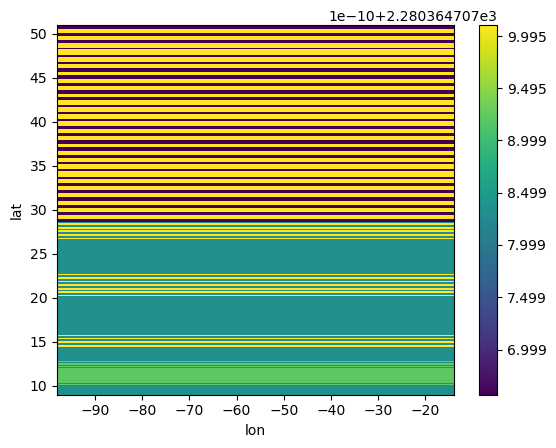

In [6]:
llo, lla = np.meshgrid(dsp.x, dsp.y)
xx = xr.DataArray(gsw.distance(llo, lla), dims=["lat","lon"],
                  coords={"lat":dsp.y.data,
                          "lon":dsp.x.rolling(x=2).mean().dropna("x").data}
                 ).interp(lon=dsp.x.data)
yy = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["lat","lon"],
                  coords={"lat":dsp.y.rolling(y=2).mean().dropna("y").data,
                          "lon":dsp.x.data}
                 ).interp(lat=dsp.y.data)
xx.plot(rasterized=True)
plt.show()
yy.plot(rasterized=True)
plt.show()

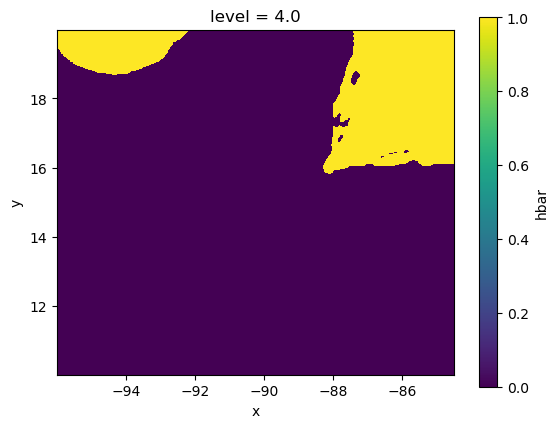

0
<xarray.Dataset> Size: 734MB
Dimensions:  (y: 487, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x        (x) float64 4kB -6.001e+05 -5.979e+05 ... 5.979e+05 6.001e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vp       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    upp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vpp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


1
<xarray.Dataset> Size: 734MB
Dimensions:  (y: 487, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x        (x) float64 4kB -6.001e+05 -5.979e+05 ... 5.979e+05 6.001e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vp       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    upp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vpp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


2
<xarray.Dataset> Size: 734MB
Dimensions:  (y: 487, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x        (x) float64 4kB -6.001e+05 -5.979e+05 ... 5.979e+05 6.001e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vp       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    upp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    vpp      (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (5 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.37 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


6
<xarray.Dataset> Size: 735MB
Dimensions:  (y: 488, x: 560, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.491e+05 5.51e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.02341 0.02634 0.02938 ... 0.0 0.0 0.0
    vp       (time, y, x) float64 184MB -0.06244 -0.06207 -0.06096 ... 0.0 0.0
    upp      (time, y, x) float64 184MB 0.02612 0.02902 0.03203 ... 0.0 0.0 0.0
    vpp      (time, y, x) float64 184MB -0.06478 -0.06425 -0.06294 ... 0.0 0.0


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


7


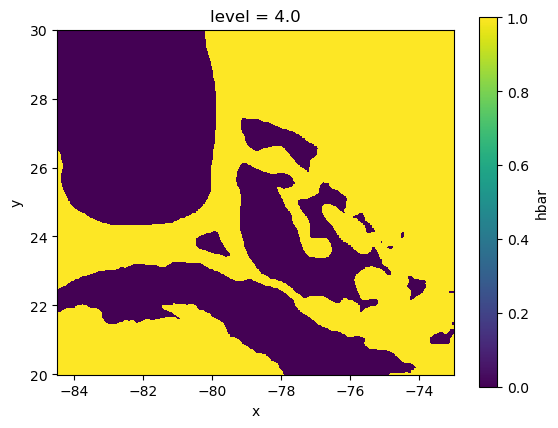

8
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.02924 0.03201 ... -0.0216 -0.02131
    vp       (time, y, x) float64 184MB -0.02142 -0.0232 ... 0.03633 0.03855
    upp      (time, y, x) float64 184MB 0.02965 0.03247 ... -0.02248 -0.02218
    vpp      (time, y, x) float64 184MB -0.02169 -0.02346 ... 0.03718 0.03927


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


9
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.1065 -0.1057 ... -0.03614 -0.03424
    vp       (time, y, x) float64 184MB 0.03583 0.03324 ... -0.129 -0.1148
    upp      (time, y, x) float64 184MB -0.1089 -0.1081 ... -0.03631 -0.03437
    vpp      (time, y, x) float64 184MB 0.03726 0.03467 ... -0.1272 -0.1128


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


10
<xarray.Dataset> Size: 735MB
Dimensions:  (y: 488, x: 560, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.491e+05 5.51e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB 0.005995 0.004316 ... -0.02085 -0.0192
    vp       (time, y, x) float64 184MB 0.03018 0.02635 ... -0.01985 -0.0174
    upp      (time, y, x) float64 184MB 0.004396 0.002751 ... -0.02129 -0.01961
    vpp      (time, y, x) float64 184MB 0.03135 0.02754 ... -0.0195 -0.0171


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


11
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.04328 -0.04377 ... -0.02712 -0.02468
    vp       (time, y, x) float64 184MB 0.07158 0.07168 ... 0.03037 0.03576
    upp      (time, y, x) float64 184MB -0.04445 -0.0449 ... -0.03039 -0.02791
    vpp      (time, y, x) float64 184MB 0.07304 0.0731 ... 0.03073 0.03614


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


12
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.1297 -0.1279 ... -0.05101 -0.0507
    vp       (time, y, x) float64 184MB -0.006906 0.0007052 ... -0.02551
    upp      (time, y, x) float64 184MB -0.132 -0.1302 ... -0.05648 -0.05641
    vpp      (time, y, x) float64 184MB -0.001898 0.00563 ... -0.02387 -0.02141


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


13


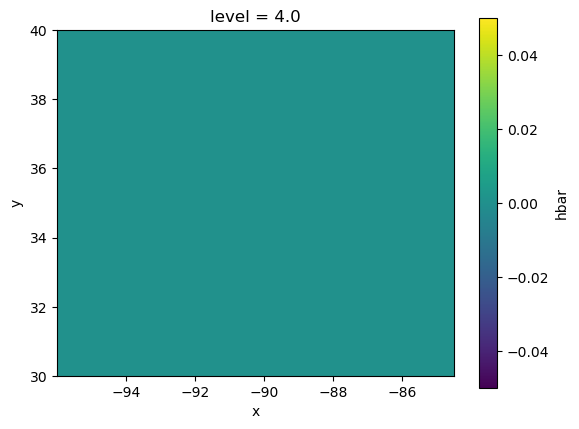

14


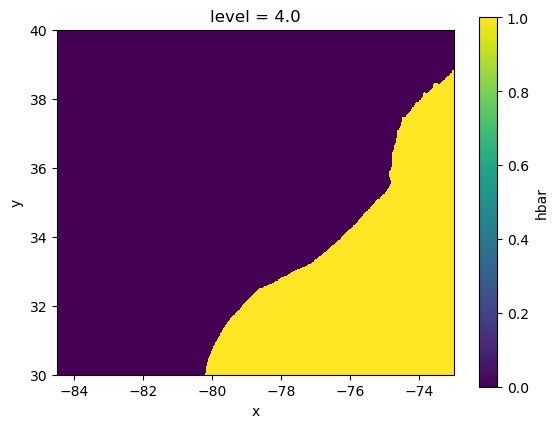

15
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.06363 -0.06187 ... -0.2055 -0.183
    vp       (time, y, x) float64 184MB 0.03916 0.03672 ... -0.9459 -0.9985
    upp      (time, y, x) float64 184MB -0.06351 -0.06173 ... -0.1709 -0.1487
    vpp      (time, y, x) float64 184MB 0.03836 0.03585 ... -0.9389 -0.9926


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


16
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.08739 -0.08531 ... -0.09186 -0.09476
    vp       (time, y, x) float64 184MB 0.001229 0.001204 ... 0.02094 0.01787
    upp      (time, y, x) float64 184MB -0.08669 -0.08458 ... -0.1096 -0.112
    vpp      (time, y, x) float64 184MB 0.0009067 0.0009019 ... 0.04468 0.04193


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


17
<xarray.Dataset> Size: 735MB
Dimensions:  (y: 488, x: 560, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.856e+05 4.874e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.005891 -0.007003 ... 0.2573 0.2499
    vp       (time, y, x) float64 184MB 0.03728 0.03829 ... 0.06594 0.06338
    upp      (time, y, x) float64 184MB -0.006957 -0.00809 ... 0.2553 0.2479
    vpp      (time, y, x) float64 184MB 0.03951 0.04043 ... 0.06766 0.06501


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 700.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


18
<xarray.Dataset> Size: 736MB
Dimensions:  (y: 488, x: 561, time: 84)
Coordinates:
  * y        (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x        (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    up       (time, y, x) float64 184MB -0.03368 -0.03607 ... -0.06902 -0.06789
    vp       (time, y, x) float64 184MB 0.00435 0.00183 ... -0.006705 -0.008947
    upp      (time, y, x) float64 184MB -0.03454 -0.03693 ... -0.06849 -0.06737
    vpp      (time, y, x) float64 184MB 0.0052 0.002725 ... -0.006887 -0.009159


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.81 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


19


In [ ]:
dtime = 5
ireg = 0
for aa in la[:-1]:

    dba  = dsb.isel(level=-1).sel(y=slice(aa,aa+10.))
    dpa  = dsp.isel(time=range(0,len(dsp.time),dtime), 
                    level=-1).sel(y=slice(aa,aa+10.))
    dppa = dspp.isel(time=range(0,len(dsp.time),dtime), 
                     level=-1).sel(y=slice(aa,aa+10.))

    if aa == la[0]:
        lolo = lo[:-1]
    else:
        lolo = lo[:-1]
    for oo in lolo:
        
        dbao  = dba.sel(x=slice(oo,oo+dlo)).load()
        maskh = ~np.ma.masked_values(dbao.hbar,0.).mask
        maskh = xr.ones_like(dbao.hbar) * maskh
            
        N = maskh.shape
    
        if (maskh.sum()) > .6*np.prod(N):
            dpao  = dpa.sel(x=slice(oo,oo+dlo)).load()
            dppao = dppa.sel(x=slice(oo,oo+dlo)).load()
            xao = xx.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lon")
            yao = yy.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lat")
            N = xao.shape
            xao_centered = xao.copy() 
            xao_centered -= xao[:,N[-1]//2]
    
            # dpao.coords["xx"] = (("y","x"), xao_centered.data)
            # dppao.coords["xx"] = (("y","x"), xao_centered.data)
            xT = xao_centered.values.flatten()
            yT = yao.values.flatten()
            grid_x, grid_y = np.meshgrid(xao_centered.isel(lat=-1),
                                         yao.mean("lon"))
            
            for tt in range(len(dpao.time)):
                if tt == 0:
                    up  = xr.DataArray(griddata((xT,yT), 
                                                dpao.up.isel(time=tt).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    upp  = xr.DataArray(griddata((xT,yT), 
                                                 dppao.upp.isel(time=tt).values.flatten(), 
                                                 (grid_x,grid_y), method="linear"),
                                        dims=["y","x"], 
                                        coords={"y":yao.mean("lon").data,
                                                "x":xao_centered.isel(lat=-1).data}
                                       )
                    vp  = xr.DataArray(griddata((xT,yT), 
                                                dpao.vp.isel(time=tt).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    vpp  = xr.DataArray(griddata((xT,yT), 
                                                 dppao.vpp.isel(time=tt).values.flatten(), 
                                                 (grid_x,grid_y), method="linear"),
                                        dims=["y","x"], 
                                        coords={"y":yao.mean("lon").data,
                                             "x":xao_centered.isel(lat=-1).data}
                                       )
                    # fig, ax = plt.subplots()
                    # up.plot(ax=ax, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                    # fig, ax = plt.subplots()
                    # upp.plot(ax=ax, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                else:
                    up = xr.concat([up,
                                    xr.DataArray(griddata((xT,yT), 
                                                          dpao.up.isel(time=tt).values.flatten(), 
                                                          (grid_x,grid_y), method="linear"),
                                                 dims=["y","x"], 
                                                 coords={"y":yao.mean("lon").data,
                                                         "x":xao_centered.isel(lat=-1).data}
                                                )], 
                                   "time")
                    upp = xr.concat([upp,
                                    xr.DataArray(griddata((xT,yT), 
                                                          dppao.upp.isel(time=tt).values.flatten(), 
                                                          (grid_x,grid_y), method="linear"),
                                                 dims=["y","x"], 
                                                 coords={"y":yao.mean("lon").data,
                                                         "x":xao_centered.isel(lat=-1).data}
                                                )], 
                                   "time")
                    vp = xr.concat([vp,
                                    xr.DataArray(griddata((xT,yT), 
                                                          dpao.vp.isel(time=tt).values.flatten(), 
                                                          (grid_x,grid_y), method="linear"),
                                                 dims=["y","x"], 
                                                 coords={"y":yao.mean("lon").data,
                                                         "x":xao_centered.isel(lat=-1).data}
                                                )], 
                                   "time")
                    vpp = xr.concat([vpp,
                                    xr.DataArray(griddata((xT,yT), 
                                                          dppao.vpp.isel(time=tt).values.flatten(), 
                                                          (grid_x,grid_y), method="linear"),
                                                 dims=["y","x"], 
                                                 coords={"y":yao.mean("lon").data,
                                                         "x":xao_centered.isel(lat=-1).data}
                                                )], 
                                   "time")
                    
            dsave = up.to_dataset(name="up")
            dsave["vp"] = vp
            dsave["upp"] = upp
            dsave["vpp"] = vpp
            print(dsave)
            dsave.chunk({"time":10,"y":-1,"x":-1}
                       ).to_zarr(op.join(ddir,"SW/TWA/%02d/U-interp.zarr" 
                                         % ireg))
            dsave.close()
            dpao.close(), dppao.close()
            del up, vp, upp, vpp
        else:
            fig, ax = plt.subplots()
            (maskh).plot(ax=ax, rasterized=True)
            ax.set_aspect("equal")
            plt.show()

        print(ireg)
        ireg += 1

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.79 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 552MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 4.703e-11 5.234e-11 ... 7.55e-11
    Piflat    (time, y, x) float64 184MB 5.468e-11 6.022e-11 ... 8.073e-11
    Pidagger  (time, y, x) float64 184MB 5.479e-11 6.031e-11 ... 8.051e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 526.36 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


13


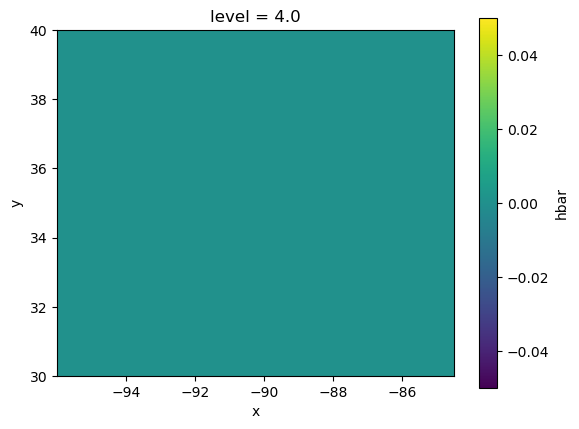

14


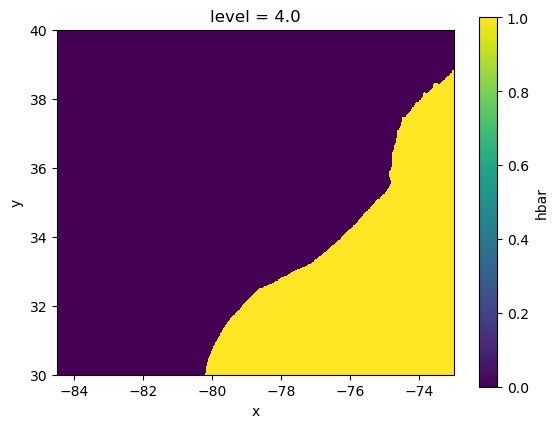

15


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.79 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 552MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 4.392e-12 3.592e-12 ... -4.174e-10
    Piflat    (time, y, x) float64 184MB 5.552e-12 4.894e-12 ... -3.782e-10
    Pidagger  (time, y, x) float64 184MB 5.497e-12 4.827e-12 ... -3.751e-10


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 526.36 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


16


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.82 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (11 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.79 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 552MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB -3.259e-11 -2.094e-11 ... 1.227e-11
    Piflat    (time, y, x) float64 184MB -1.721e-11 -5.225e-12 ... 1.865e-11
    Pidagger  (time, y, x) float64 184MB -1.746e-11 -5.479e-12 ... 1.843e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 526.36 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


20


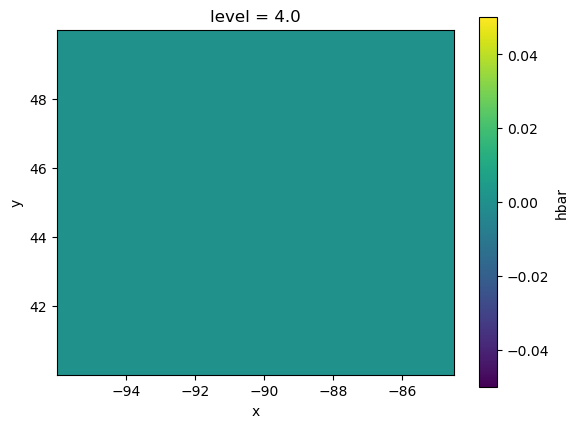

21


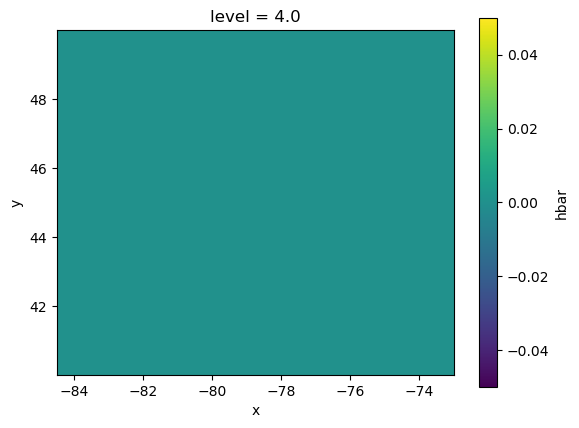

22


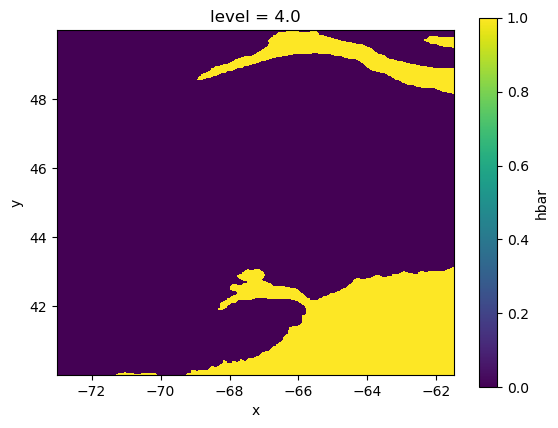

23


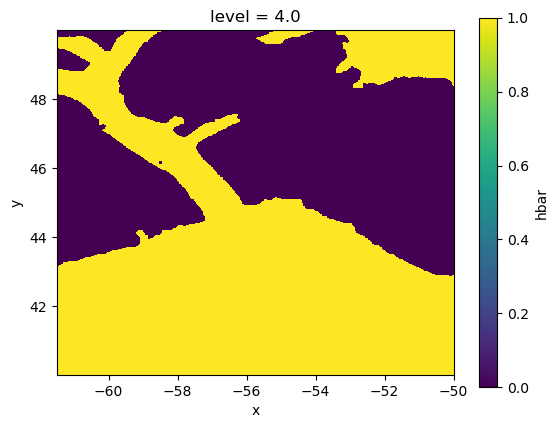

24


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.93 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 550MB
Dimensions:   (y: 487, x: 560, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x         (x) float64 4kB -4.106e+05 -4.091e+05 ... 4.076e+05 4.091e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 183MB -9.493e-10 -9.502e-10 ... -2.186e-10
    Piflat    (time, y, x) float64 183MB -6.033e-10 -6.028e-10 ... -2.059e-10
    Pidagger  (time, y, x) float64 183MB -5.956e-10 -5.951e-10 ... -2.11e-10


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 524.34 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


25


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.93 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (3 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 16.93 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 551MB
Dimensions:   (y: 487, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x         (x) float64 4kB -4.106e+05 -4.091e+05 ... 4.091e+05 4.106e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 3.636e-11 4.912e-11 ... 6.126e-11
    Piflat    (time, y, x) float64 184MB 4.849e-11 6.114e-11 ... 7.032e-11
    Pidagger  (time, y, x) float64 184MB 4.835e-11 6.102e-11 ... 7.028e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 525.28 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


27


In [7]:
dtime = 5
ireg = 13
for aa in la[1:-1]:

    dba  = dsb.isel(level=-1).sel(y=slice(aa,aa+10.))
    dpva  = dpvb2z.isel(time=range(0,len(dpvb2z.time),dtime),
                        Z=-3
                       ).sel(y=slice(aa,aa+10.))

    if aa == la[1]:
        lolo = lo[-2:-1]
    else:
        lolo = lo[:-1]
    for oo in lolo:
        
        dbao  = dba.sel(x=slice(oo,oo+dlo)).load()
        maskh = ~np.ma.masked_values(dbao.hbar,0.).mask
        maskh = xr.ones_like(dbao.hbar) * maskh
            
        N = maskh.shape
    
        if (maskh.sum()) > .6*np.prod(N):
            dpvao  = dpva.sel(x=slice(oo,oo+dlo)).load()
            xao = xx.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lon")
            yao = yy.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lat")
            N = xao.shape
            xao_centered = xao.copy() 
            xao_centered -= xao[:,N[-1]//2]
    
            # dpao.coords["xx"] = (("y","x"), xao_centered.data)
            # dppao.coords["xx"] = (("y","x"), xao_centered.data)
            xT = xao_centered.values.flatten()
            yT = yao.values.flatten()
            grid_x, grid_y = np.meshgrid(xao_centered.isel(lat=-1),
                                         yao.mean("lon"))
            
            for tt in range(len(dpvao.time)):
                if tt == 0:
                    pvp  = xr.DataArray(griddata((xT,yT), 
                                                dpvao.Pip.isel(time=tt).fillna(0.).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    pvd  = xr.DataArray(griddata((xT,yT), 
                                                dpvao.Pidagger.isel(time=tt).fillna(0.).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    pvf  = xr.DataArray(griddata((xT,yT), 
                                                 dpvao.Piflat.isel(time=tt).fillna(0.).values.flatten(), 
                                                 (grid_x,grid_y), method="linear"),
                                        dims=["y","x"], 
                                        coords={"y":yao.mean("lon").data,
                                                "x":xao_centered.isel(lat=-1).data}
                                       )
                    # fig, ax = plt.subplots()
                    # pvp.plot(ax=ax, vmax=2e-7, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                    # fig, ax = plt.subplots()
                    # pvf.plot(ax=ax, vmax=2e-7, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                else:
                    pvp = xr.concat([pvp,
                                xr.DataArray(griddata((xT,yT), 
                                                      dpvao.Pip.isel(time=tt).fillna(0.).values.flatten(), 
                                                      (grid_x,grid_y), method="linear"),
                                             dims=["y","x"], 
                                             coords={"y":yao.mean("lon").data,
                                                     "x":xao_centered.isel(lat=-1).data}
                                            )], 
                                   "time")
                    pvd = xr.concat([pvd,
                                xr.DataArray(griddata((xT,yT), 
                                                      dpvao.Pidagger.isel(time=tt).fillna(0.).values.flatten(), 
                                                      (grid_x,grid_y), method="linear"),
                                             dims=["y","x"], 
                                             coords={"y":yao.mean("lon").data,
                                                     "x":xao_centered.isel(lat=-1).data}
                                            )], 
                                   "time")
                    pvf = xr.concat([pvf,
                                xr.DataArray(griddata((xT,yT), 
                                                      dpvao.Piflat.isel(time=tt).fillna(0.).values.flatten(), 
                                                      (grid_x,grid_y), method="linear"),
                                             dims=["y","x"], 
                                             coords={"y":yao.mean("lon").data,
                                                     "x":xao_centered.isel(lat=-1).data}
                                            )], 
                                   "time")
                    
            dsave = pvp.to_dataset(name="Pip")
            dsave["Piflat"] = pvf
            dsave["Pidagger"] = pvd
            print(dsave)
            dsave.chunk({"time":10,"y":-1,"x":-1}
                       ).to_zarr(op.join(ddir,"SW/TWA/%02d/PV-interp.zarr" 
                                         % ireg), 
                                 mode="w")
            dsave.close()
            dpvao.close()
            del pvp, pvd, pvf
        else:
            fig, ax = plt.subplots()
            (maskh).plot(ax=ax, rasterized=True)
            ax.set_aspect("equal")
            plt.show()

        print(ireg)
        ireg += 1

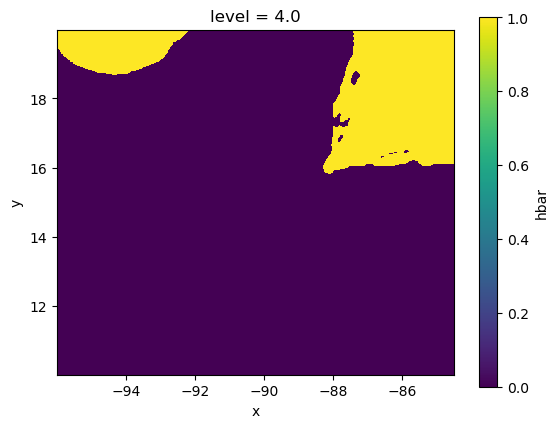

0


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.29 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 367MB
Dimensions:   (y: 487, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x         (x) float64 4kB -6.001e+05 -5.979e+05 ... 5.979e+05 6.001e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan
    Pidagger  (time, y, x) float64 184MB 0.0 0.0 0.0 0.0 0.0 ... nan nan nan nan


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.19 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


1


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.29 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (19 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 367MB
Dimensions:   (y: 488, x: 560, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.491e+05 5.51e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 3.967e-11 4.766e-11 ... 0.0 0.0
    Pidagger  (time, y, x) float64 184MB 4.141e-11 4.939e-11 ... 0.0 0.0


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.28 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


7


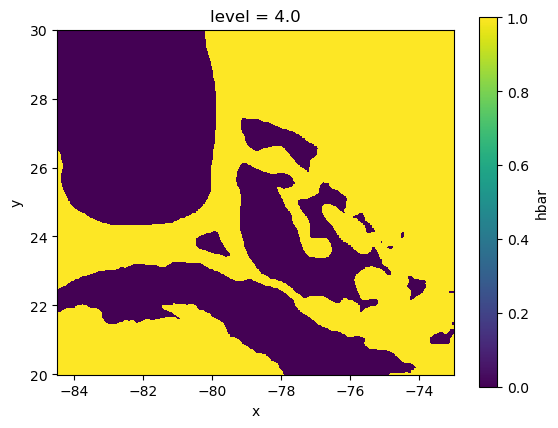

8


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 368MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB -1.419e-10 -1.389e-10 ... -7.221e-11
    Pidagger  (time, y, x) float64 184MB -1.408e-10 -1.378e-10 ... -6.935e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


9


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.21 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (11 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 368MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -5.53e+05 -5.51e+05 ... 5.51e+05 5.53e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 5.249e-11 5.779e-11 ... 5.266e-11
    Pidagger  (time, y, x) float64 184MB 5.878e-11 6.413e-11 ... 5.571e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


13


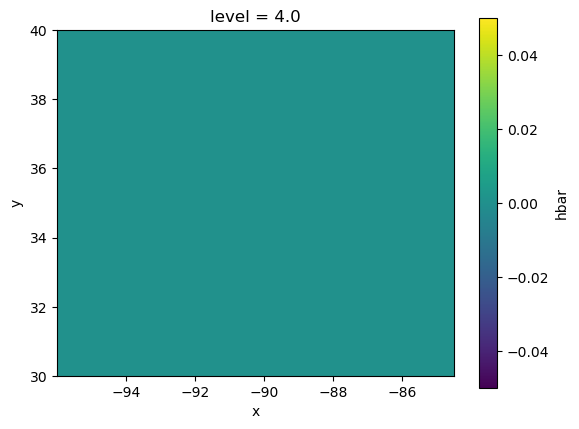

14


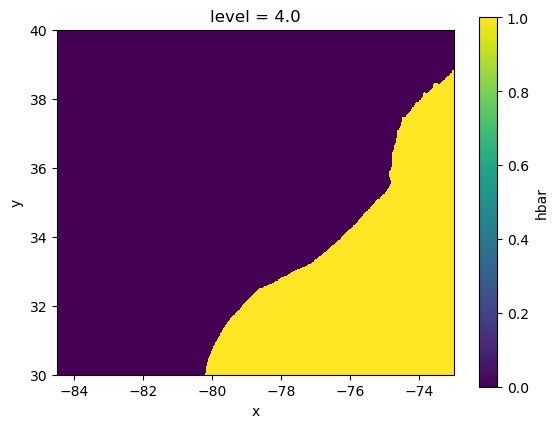

15


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 368MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB 1.689e-11 1.624e-11 ... -1.779e-10
    Pidagger  (time, y, x) float64 184MB 1.929e-11 1.864e-11 ... -1.417e-10


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


16


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.21 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (11 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.20 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 368MB
Dimensions:   (y: 488, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.111e+06 1.113e+06
  * x         (x) float64 4kB -4.891e+05 -4.874e+05 ... 4.874e+05 4.891e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB -2.646e-11 -1.454e-11 ... 3.209e-11
    Pidagger  (time, y, x) float64 184MB -2.007e-11 -8.156e-12 ... 3.599e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.91 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


20


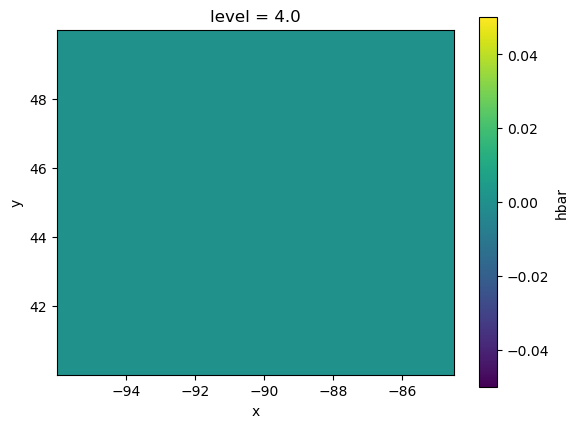

21


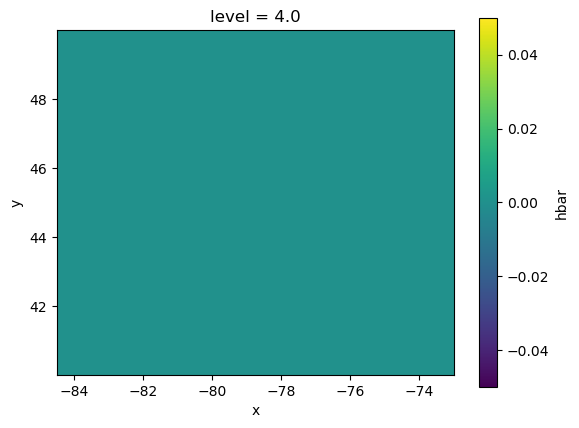

22


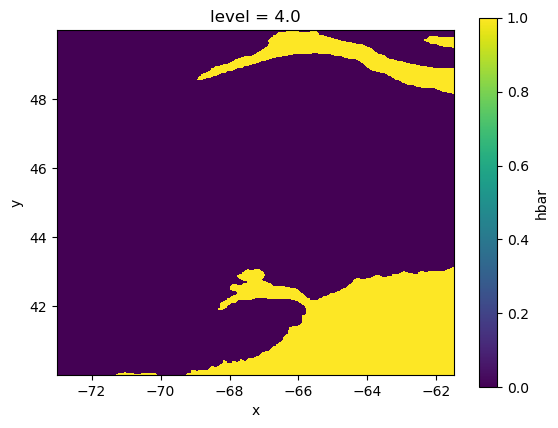

23


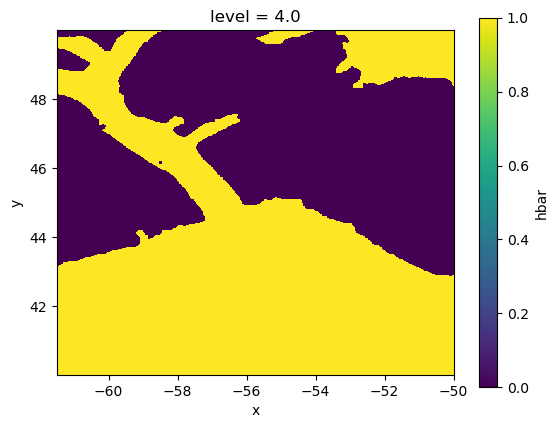

24


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.29 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 367MB
Dimensions:   (y: 487, x: 560, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x         (x) float64 4kB -4.106e+05 -4.091e+05 ... 4.076e+05 4.091e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 183MB -3.044e-10 -3.059e-10 ... -9.89e-11
    Pidagger  (time, y, x) float64 183MB -2.649e-10 -2.657e-10 ... -8.805e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 349.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


25


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.29 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


... (3 outputs left out)

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 11.29 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


<xarray.Dataset> Size: 367MB
Dimensions:   (y: 487, x: 561, time: 84)
Coordinates:
  * y         (y) float64 4kB 2.28e+03 4.561e+03 ... 1.108e+06 1.111e+06
  * x         (x) float64 4kB -4.106e+05 -4.091e+05 ... 4.091e+05 4.106e+05
Dimensions without coordinates: time
Data variables:
    Pip       (time, y, x) float64 184MB -1.26e-10 -1.136e-10 ... 4.954e-11
    Pidagger  (time, y, x) float64 184MB -1.146e-10 -1.022e-10 ... 5.013e-11


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 350.19 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


27


In [10]:
dtime = 5
ireg = 0
for aa in la[:-1]:

    dba  = dsb.isel(level=-1).sel(y=slice(aa,aa+10.))
    dpva  = dpvz.isel(time=range(0,len(dpvz.time),dtime),
                      Z=-3
                     ).sel(y=slice(aa,aa+10.))

    if aa == la[0]:
        lolo = lo[:-1]
    else:
        lolo = lo[:-1]
    for oo in lolo:
        
        dbao  = dba.sel(x=slice(oo,oo+dlo)).load()
        maskh = ~np.ma.masked_values(dbao.hbar,0.).mask
        maskh = xr.ones_like(dbao.hbar) * maskh
            
        N = maskh.shape
    
        if (maskh.sum()) > .6*np.prod(N):
            dpvao  = dpva.sel(x=slice(oo,oo+dlo)).load()
            xao = xx.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lon")
            yao = yy.sel(lat=slice(aa,aa+10.),
                         lon=slice(oo,oo+dlo)).cumsum("lat")
            N = xao.shape
            xao_centered = xao.copy() 
            xao_centered -= xao[:,N[-1]//2]
    
            # dpao.coords["xx"] = (("y","x"), xao_centered.data)
            # dppao.coords["xx"] = (("y","x"), xao_centered.data)
            xT = xao_centered.values.flatten()
            yT = yao.values.flatten()
            grid_x, grid_y = np.meshgrid(xao_centered.isel(lat=-1),
                                         yao.mean("lon"))
            
            for tt in range(len(dpvao.time)):
                if tt == 0:
                    pvp  = xr.DataArray(griddata((xT,yT), 
                                                dpvao.Pip.isel(time=tt).fillna(0.).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    pvd  = xr.DataArray(griddata((xT,yT), 
                                                dpvao.Pidagger.isel(time=tt).fillna(0.).values.flatten(), 
                                                (grid_x,grid_y), method="linear"),
                                       dims=["y","x"], 
                                       coords={"y":yao.mean("lon").data,
                                               "x":xao_centered.isel(lat=-1).data}
                                      )
                    # fig, ax = plt.subplots()
                    # pvp.plot(ax=ax, vmax=2e-7, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                    # fig, ax = plt.subplots()
                    # pvf.plot(ax=ax, vmax=2e-7, rasterized=True)
                    # ax.set_aspect("equal")
                    # plt.show()
                else:
                    pvp = xr.concat([pvp,
                                xr.DataArray(griddata((xT,yT), 
                                                      dpvao.Pip.isel(time=tt).fillna(0.).values.flatten(), 
                                                      (grid_x,grid_y), method="linear"),
                                             dims=["y","x"], 
                                             coords={"y":yao.mean("lon").data,
                                                     "x":xao_centered.isel(lat=-1).data}
                                            )], 
                                   "time")
                    pvd = xr.concat([pvd,
                                xr.DataArray(griddata((xT,yT), 
                                                      dpvao.Pidagger.isel(time=tt).fillna(0.).values.flatten(), 
                                                      (grid_x,grid_y), method="linear"),
                                             dims=["y","x"], 
                                             coords={"y":yao.mean("lon").data,
                                                     "x":xao_centered.isel(lat=-1).data}
                                            )], 
                                   "time")
                    
            dsave = pvp.to_dataset(name="Pip")
            # dsave["Piflat"] = pvf
            dsave["Pidagger"] = pvd
            print(dsave)
            dsave.chunk({"time":10,"y":-1,"x":-1}
                       ).to_zarr(op.join(ddir,"SW/TWA/%02d/PVinZ-interp.zarr" 
                                         % ireg), 
                                 mode="w")
            dsave.close()
            dpvao.close()
            del pvp, pvd
        else:
            fig, ax = plt.subplots()
            (maskh).plot(ax=ax, rasterized=True)
            ax.set_aspect("equal")
            plt.show()

        print(ireg)
        ireg += 1